In [1]:
import pandas as pd, numpy as np

panel = pd.read_parquet("../data/processed/weekly_demand.parquet")
panel["week"] = pd.to_datetime(panel["week"])
groups = pd.read_parquet("../data/processed/product_groups.parquet").set_index("StockCode")["group"]

wide = panel.pivot(index="week", columns="StockCode", values="units_regular").sort_index()
test_weeks = wide.index[-12:]
MIN_WEEK = wide.index[8]

ALPHA = 0.2     # smoothing level chosen on the validation weeks in 06_model
ewma_pred = {h: wide.ewm(alpha=ALPHA, adjust=False).mean().shift(h) for h in [1, 2]}
print(wide.shape, test_weeks[0].date(), test_weeks[-1].date())

(52, 60) 2011-09-12 2011-11-28


In [4]:
import pandas as pd, numpy as np

panel = pd.read_parquet("../data/processed/weekly_demand.parquet")
panel["week"] = pd.to_datetime(panel["week"])
groups = pd.read_parquet("../data/processed/product_groups.parquet").set_index("StockCode")["group"]

wide = panel.pivot(index="week", columns="StockCode", values="units_regular").sort_index()
test_weeks = wide.index[-12:]
MIN_WEEK = wide.index[8]

ALPHA = 0.2     # smoothing level chosen on the validation weeks in 06_model
ewma_pred = {h: wide.ewm(alpha=ALPHA, adjust=False).mean().shift(h) for h in [1, 2]}
print(wide.shape, test_weeks[0].date(), test_weeks[-1].date())

(52, 60) 2011-09-12 2011-11-28


In [6]:
def S_quantile(h, p, window=8):
    f = ewma_pred[h]
    denom = f.clip(lower=1)
    rel_err = (wide - f) / denom
    out = {}
    for t in test_weeks:
        cutoff = t - pd.Timedelta(weeks=h)
        start = max(MIN_WEEK, cutoff - pd.Timedelta(weeks=window - 1))
        past = rel_err.loc[(rel_err.index >= start) & (rel_err.index <= cutoff)]
        vals = past.to_numpy().ravel()
        vals = vals[~np.isnan(vals)]
        out[t] = f.loc[t] + np.quantile(vals, p) * denom.loc[t]
    return pd.DataFrame(out).T.clip(lower=0)

def simulate(S, cols=None):
    a = wide.loc[test_weeks]
    S = S.loc[test_weeks]
    if cols is not None:
        a, S = a[cols], S[cols]
    left = pd.Series(0.0, index=a.columns)
    sold = demand = stock_sum = 0.0
    short = n = 0
    for t in test_weeks:
        stock = np.maximum(S.loc[t], left)
        d = a.loc[t]
        s = np.minimum(stock, d)
        sold += s.sum()
        demand += d.sum()
        stock_sum += stock.sum()
        short += int((d > stock).sum())
        n += len(d)
        left = stock - s
    return {"fill_rate": float(sold / demand), "stockout_rate": float(short / n),
            "stock_cover": float(stock_sum / demand)}

           policy  param  fill_rate  stockout_rate  stock_cover
naive (last week)    NaN      0.798          0.474        1.027
     fixed buffer   0.00      0.766          0.536        0.897
     fixed buffer   0.10      0.810          0.456        0.986
     fixed buffer   0.20      0.847          0.385        1.076
     fixed buffer   0.30      0.877          0.311        1.166
     fixed buffer   0.50      0.925          0.214        1.346
     fixed buffer   0.75      0.962          0.124        1.571
     fixed buffer   1.00      0.980          0.064        1.796
     fixed buffer   1.50      0.994          0.022        2.246
   interval-based   0.50      0.772          0.526        0.910
   interval-based   0.60      0.829          0.421        1.031
   interval-based   0.70      0.871          0.321        1.148
   interval-based   0.80      0.927          0.206        1.358
   interval-based   0.90      0.970          0.103        1.651
   interval-based   0.95      0.987     

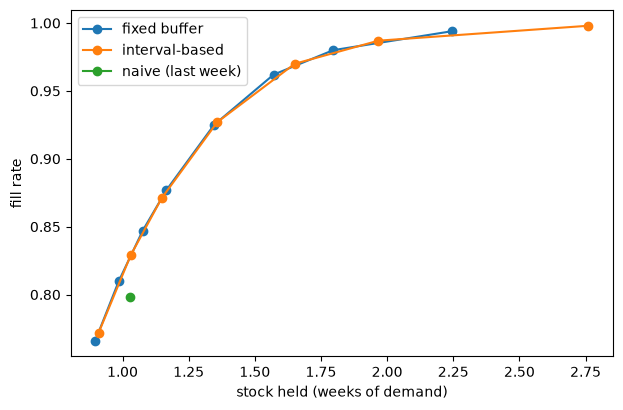

stock needed (weeks of demand) for a target fill rate, interpolated:
0.9 {'fixed buffer': 1.252, 'interval-based': 1.257}
0.95 {'fixed buffer': 1.498, 'interval-based': 1.515}
0.98 {'fixed buffer': 1.796, 'interval-based': 1.837}


In [7]:
H = 1          # forecast horizon / lead time in weeks; change to 2 and re-run for the 2-week case
buffers = [0, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5]
levels = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.98]

rows = [{"policy": "naive (last week)", "param": np.nan, **simulate(wide.shift(H))}]
for b in buffers:
    rows.append({"policy": "fixed buffer", "param": b, **simulate(ewma_pred[H] * (1 + b))})
for p in levels:
    rows.append({"policy": "interval-based", "param": p, **simulate(S_quantile(H, p))})
sweep = pd.DataFrame(rows).round(3)
print(sweep.to_string(index=False))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, grp in sweep.groupby("policy"):
    ax.plot(grp["stock_cover"], grp["fill_rate"], marker="o", label=name)
ax.set_xlabel("stock held (weeks of demand)")
ax.set_ylabel("fill rate")
ax.legend()
plt.show()

print("stock needed (weeks of demand) for a target fill rate, interpolated:")
for target in [0.90, 0.95, 0.98]:
    out = {}
    for name in ["fixed buffer", "interval-based"]:
        g = sweep[sweep["policy"] == name].sort_values("fill_rate")
        out[name] = round(float(np.interp(target, g["fill_rate"], g["stock_cover"])), 3)
    print(target, out)

In [4]:
TARGET = 0.95
def pick(policy_rows):
    ok = policy_rows[policy_rows["fill_rate"] >= TARGET]
    return ok.iloc[0] if len(ok) else policy_rows.iloc[-1]

fb = pick(sweep[sweep["policy"] == "fixed buffer"])
iv = pick(sweep[sweep["policy"] == "interval-based"])
print("fixed buffer:", fb["param"], "| interval-based level:", iv["param"])

rows = []
for g in ["all", "stable", "intermittent", "seasonal_ramp"]:
    cols = None if g == "all" else groups[groups == g].index
    rows.append({"group": g, "policy": "naive", **simulate(wide.shift(H), cols)})
    rows.append({"group": g, "policy": "fixed buffer", **simulate(ewma_pred[H] * (1 + fb["param"]), cols)})
    rows.append({"group": g, "policy": "interval-based", **simulate(S_quantile(H, iv["param"]), cols)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

fixed buffer: 0.75 | interval-based level: 0.9
        group         policy  fill_rate  stockout_rate  stock_cover
          all          naive      0.798          0.474        1.027
          all   fixed buffer      0.962          0.124        1.571
          all interval-based      0.970          0.103        1.651
       stable          naive      0.793          0.456        1.041
       stable   fixed buffer      0.975          0.083        1.692
       stable interval-based      0.980          0.070        1.778
 intermittent          naive      0.759          0.486        1.171
 intermittent   fixed buffer      0.913          0.208        1.511
 intermittent interval-based      0.924          0.153        1.592
seasonal_ramp          naive      0.830          0.556        0.926
seasonal_ramp   fixed buffer      0.936          0.269        1.179
seasonal_ramp interval-based      0.950          0.231        1.238


In [5]:
def S_volatility(h, k, window=8):
    f = ewma_pred[h]
    err = wide - f
    rms = (err ** 2).rolling(window, min_periods=4).mean().pow(0.5).shift(h)
    return (f + k * rms).clip(lower=0)

ks = [0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
rows2 = [{"policy": "volatility-based", "param": k, **simulate(S_volatility(H, k))} for k in ks]
sweep2 = pd.concat([sweep, pd.DataFrame(rows2).round(3)], ignore_index=True)
print(sweep2[sweep2["policy"] == "volatility-based"].to_string(index=False))

print("stock needed (weeks of demand) for a target fill rate, interpolated:")
for target in [0.90, 0.95, 0.98]:
    out = {}
    for name in ["fixed buffer", "interval-based", "volatility-based"]:
        g = sweep2[sweep2["policy"] == name].sort_values("fill_rate")
        out[name] = round(float(np.interp(target, g["fill_rate"], g["stock_cover"])), 3)
    print(target, out)

          policy  param  fill_rate  stockout_rate  stock_cover
volatility-based    0.0      0.766          0.536        0.897
volatility-based    0.5      0.859          0.360        1.112
volatility-based    1.0      0.919          0.225        1.329
volatility-based    1.5      0.956          0.139        1.545
volatility-based    2.0      0.976          0.081        1.762
volatility-based    2.5      0.986          0.053        1.979
volatility-based    3.0      0.992          0.028        2.197
stock needed (weeks of demand) for a target fill rate, interpolated:
0.9 {'fixed buffer': 1.252, 'interval-based': 1.257, 'volatility-based': 1.26}
0.95 {'fixed buffer': 1.498, 'interval-based': 1.515, 'volatility-based': 1.51}
0.98 {'fixed buffer': 1.796, 'interval-based': 1.837, 'volatility-based': 1.849}


- Buffered ordering raises fill rate from 79.8% to about 96-97%, but mostly by holding 53-61% more stock. Compared at matched stock, the EWMA forecast with a buffer serves about 82.7% of demand vs 79.8% for naive (about +3 points), or needs about 6% less stock (0.96 vs 1.03 weeks) for the same fill rate.
- At matched fill rate the interval-based rule and the fixed buffer are equivalent (stock needed: 1.25 vs 1.26 weeks at 90%, 1.50 vs 1.52 at 95%, 1.80 vs 1.84 at 98%). Both set the margin as a percentage of the forecast, so the pooled error quantiles add nothing over a flat buffer.

In [3]:
import os

ALPHA = 0.2
LEVELS = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.98]

def long(df, name):
    d = df.rename_axis(index="week", columns="StockCode")
    return d.reset_index().melt(id_vars="week", var_name="StockCode", value_name=name)

# 1) weekly table: actual demand, 1-week-ahead forecast, 80% range (test weeks only)
lo1 = S_quantile(1, 0.10)
hi1 = S_quantile(1, 0.90)
weekly = long(wide, "actual")
for name, frame in {"forecast": ewma_pred[1], "lower": lo1, "upper": hi1}.items():
    weekly = weekly.merge(long(frame, name), on=["week", "StockCode"], how="left")

# 2) next-week forecast and order-up-to levels
f1 = ewma_pred[1]
rel_err = ((wide - f1) / f1.clip(lower=1)).iloc[-8:]          # last 8 known weeks of errors
vals = rel_err.to_numpy().ravel()
vals = vals[~np.isnan(vals)]
q = {p: float(np.quantile(vals, p)) for p in LEVELS}
f_next = wide.ewm(alpha=ALPHA, adjust=False).mean().iloc[-1]
next_week = pd.DataFrame({"StockCode": f_next.index, "forecast": f_next.values})
for p in LEVELS:
    next_week[f"s_{int(round(p * 100))}"] = (f_next + q[p] * f_next.clip(lower=1)).clip(lower=0).values

# 3) product descriptions and group labels
clean = pd.read_parquet("../data/processed/clean_sales.parquet", columns=["StockCode", "Description"])
clean = clean[clean["StockCode"].isin(wide.columns)]
desc = clean.groupby("StockCode")["Description"].agg(lambda s: s.mode().iat[0])
weekly["description"] = weekly["StockCode"].map(desc)
weekly["group"] = weekly["StockCode"].map(groups)
next_week["description"] = next_week["StockCode"].map(desc)

# 4) policy comparison for both horizons
def build_sweep(H):
    rows = [{"policy": "naive (last week)", "param": np.nan, **simulate(wide.shift(H))}]
    for b in [0, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5]:
        rows.append({"policy": "fixed buffer", "param": b, **simulate(ewma_pred[H] * (1 + b))})
    for p in LEVELS:
        rows.append({"policy": "interval-based", "param": p, **simulate(S_quantile(H, p))})
    out = pd.DataFrame(rows).round(3)
    out.insert(0, "horizon", H)
    return out

policy_sweep = pd.concat([build_sweep(1), build_sweep(2)], ignore_index=True)

os.makedirs("../app/data", exist_ok=True)
weekly.to_csv("../app/data/weekly.csv", index=False)
next_week.to_csv("../app/data/next_week.csv", index=False)
policy_sweep.to_csv("../app/data/policy_sweep.csv", index=False)
print(weekly.shape, next_week.shape, policy_sweep.shape)
print(next_week.head(3))


NameError: name 'ewma_pred' is not defined